# Assignment 02 - Transforms

This assignment covers robustness testing using data transforms with PyTorch and TorchVision.

## Introduction

As we have seen in class, PyTorch and its related packages provide a powerful means of transforming data in a way that is decoupled from the actual code in our training loop.

The `torch.utils.data.Dataset` and `torch.utils.data.DataLoader` classes provide interfaces for accessing datasets and loading data into our training pipelines. When combined with `torchvision.transforms`, these tools allow us to transform our data without making changes to our core training code. This is incredibly useful for data augmentation, domain generalization, and robustness testing.

For *data augmentation*, transforms can be applied before training to produce useful variation in the dataset, and instill expert knowledge into our models by having experts select which transforms we apply to the training data (e.g., applying rotations to a model which must be rotation invariant), potentially improving model generalization.

Data augmentation is one means to achieve *domain generalization*, i.e., training a model to perform well on domains not encountered during training. Transforms can be applied during training to help us improve our model's ability to generalize to new domains. For example, varying the color of the background randomly ensures the model is not incorrectly sensitive to background color and will not break in a domain with different background colors.

For robustness testing, transforms can be applied after training to assess our model's robustness to controlled perturbations applied to the evaluation data, e.g., blur, color changes, perspective changes, and other variations. We can apply transforms to various degrees using the parameters that PyTorch exposes to adjust the transform. This enables us to extract performance curves for our models which go beyond simply displaying a confusion matrix as the output of model training and show the practical limitations that the model will have when encountering variation from the training data.

This assignment will focus on applying transforms for robustness testing.

## Development and Computing Environment

For this assignment, you may use whichever computing environment you like, whether that be your local computer, Amarel, or another environment. In subsequent assignments, Amarel will be required due to the compute workloads we will need so it is recommended (though not yet required) to begin familiarizing yourself with it and employing it for assignments.

## Directions

In this assignment, we will train a model and assess its robustness using PyTorch. To do this, we will carry out the following steps.

1. **Load Data**: This step will require us to import a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms and assessing accuracy of classification tasks). Datasets built into PyTorch may be used. **0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly. As always, be sure to divide your dataset into separate training and test sets.

2. **Define the Training Pipeline**: This step will require us to define the class which specifies our neural network architecture, and to define the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments. Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

3. **Train the Model**: In this step we will use our training functions from step #2 to train a model. Once the model is trained, report baseline test accuracy on untransformed images.

4. **Use Transforms to Test the Model's Robustness Against Blur**: In this step, we will test the model for robustness against an image blur transform. This step will require us to run model inference on the **test** set repeatedly, increasing the amount of image blur with each run. For each image blur level, we will need to save the accuracy, then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur), including the baseline accuracy with no blur in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity, aiming to characterize the model's limitations. If performance does not fall to random chance within that range, explain this in your results.

5. **Robustness Test the Model Against a Transform of Your Choice**: In this step, we will test the model for robustness against a transform of our choice (perhaps perspective changes, color changes, or contrast changes). Like Step 4, this step will require us to run inference on the test set with increasing degrees of transformation and plot the resulting accuracy.

## Grading

This assignment is entirely open ended and will not be auto-graded. Each step is worth 20% of the assignment grade. For each step, ensure the following conditions are met to get full credit.

| **Step** | **Criteria for Full Credit** |
|----|----|
| 1. Data Loading | An appropriate image classification dataset is loaded using Dataset and DataLoader, separate training and test sets are established, and example images are visualized. |
| 2. Training Pipeline Definition | A suitable neural network architecture and functional training pipeline are implemented without code errors. |
| 3. Training | The model trains for a sufficient number of epochs, training loss decreases, and baseline test accuracy is reported. |
| 4. Robustness Test - Blur  | A curve of accuracy with respect to degree of blur is produced over a meaningful range of blur severity and is of professional quality. |
| 5. Robustness Test - Other  | A curve of accuracy with respect to degree of transformation over a meaningful range of transformation severity is produced and is of professional quality. |

## Tips

This assignment is intentionally open ended. **No starter code is provided.** The goal of this assignment is to test your ability to put the concepts we have discussed in class into practice.

The steps should be similar, but not necessarily exactly the same, as steps we have discussed in class.

## Imports

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt



## Step 1 - Load Data

Use the cell below (or make additional cells) to load a torch Dataset and use a torch DataLoader to access it. You may use any dataset you like, as long as it supports image classification (since this assignment is focused on image transforms). Datasets built into PyTorch may be used.

**0.25 points extra credit will be awarded for implementing a custom Dataset.** Be sure to pick a dataset you have the capacity to train a model on in your development environment. To keep the assignment fair, grading will not be based on the size of the dataset used in any way. Plot a few of the images to ensure you have loaded the data correctly.


Training images: 60000
Testing images: 10000


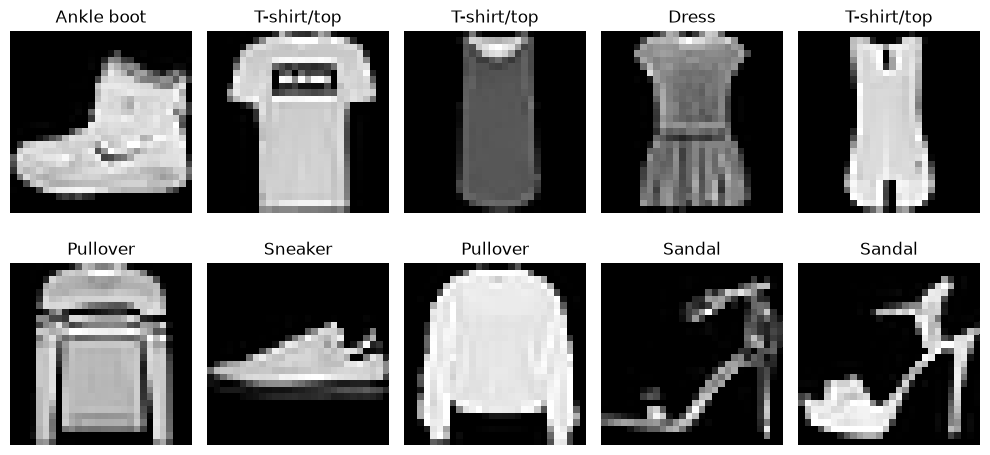

In [20]:

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Load Fashion-MNIST training and test datasets
train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

# Display dataset information
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

# Visualize example images
class_names = train_dataset.classes

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


## Step 2 - Define Training Pipeline

Define a training pipeline like those we have seen in class. Define the class that specifies our neural network architecture and the functions which allow us to train it. We have seen examples of this before, both in class and prior assignments.

Be sure to choose an architecture with sufficient capacity to learn the dataset you have chosen in step #1.

Tip: if you see your architecture is insufficient to learn the dataset you have chosen when you run step 3, you may need to return to step #2 to make your architecture wider or deeper.

In [21]:

# Define a Convolutional Neural Network (CNN)
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# Define the training function
def train_model(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


# Define the evaluation function
def evaluate_model(model, loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total


print("Neural network and training functions defined!")


Neural network and training functions defined!


## Step 3 - Train a Model

Kick off your training run here. Be sure to print or plot the error with respect to the number of epochs so you can see if your model is learning. Once training is complete, report the model's baseline accuracy on the untransformed test set.


Using device: mps
Epoch 1/5 - Training Loss: 0.4685
Epoch 2/5 - Training Loss: 0.2967
Epoch 3/5 - Training Loss: 0.2511
Epoch 4/5 - Training Loss: 0.2224
Epoch 5/5 - Training Loss: 0.1962

Baseline Test Accuracy: 91.66%


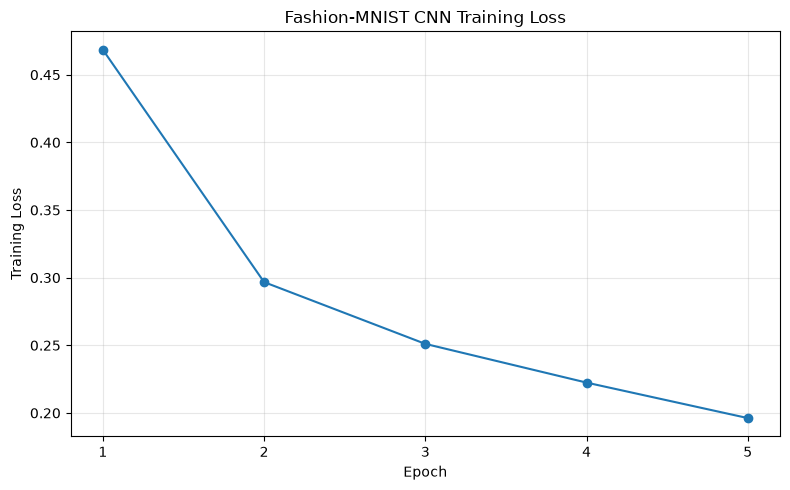

In [22]:

# Select computing device
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Using device:", device)

# Initialize model
torch.manual_seed(42)
model = FashionCNN().to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train for 5 epochs
num_epochs = 5
training_losses = []

for epoch in range(num_epochs):
    loss = train_model(
        model, train_loader, criterion, optimizer, device
    )
    training_losses.append(loss)

    print(f"Epoch {epoch + 1}/{num_epochs} - Training Loss: {loss:.4f}")

# Calculate baseline test accuracy
baseline_accuracy = evaluate_model(model, test_loader, device)

print(f"\nBaseline Test Accuracy: {baseline_accuracy:.2f}%")

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), training_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Fashion-MNIST CNN Training Loss")
plt.xticks(range(1, num_epochs + 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 4 - Use Transforms to Robustness Test the Model Against Image Blur

Use the cell below (or add more cells) to write code which repeatedly (e.g., in a for-loop) infers your model on your test set. Each time you do so, apply a blur transform with an increasing amount of blur. Compute and save the average accuracy across the entire test set and then plot the accuracy against the degree of blur (choose an appropriate metric for the degree of blur). Be sure to include the baseline accuracy with no blur applied in the plot. The end result of this step should be a plot of accuracy with respect to degree of blur. Test over a meaningful range of blur severity to characterize the model's limitations. If the model does not fail within that range, explain this in your results.

Include a brief discussion of what your results indicate about the robustness and limitations of your model.


The results show that it can perform very good and the on untransformed MNIST made images and get a baseline accuracy of 91.66%. As Gaussian blur grows the models accuracy drops and the  blur severity of 2 accuracy drops to 49.90%. With the severity of 5, it falls to 17.52%. This indicates that the model focues  on visual details of edges and textures to classify clothing. So the model is effective on clear images but becomes less reliable when those details are removed through blurring.

Blur sigma: 0 | Accuracy: 91.66%
Blur sigma: 0.5 | Accuracy: 90.80%
Blur sigma: 1 | Accuracy: 82.26%
Blur sigma: 2 | Accuracy: 49.90%
Blur sigma: 3 | Accuracy: 25.45%
Blur sigma: 5 | Accuracy: 17.52%
Blur sigma: 7 | Accuracy: 10.86%
Blur sigma: 10 | Accuracy: 10.14%


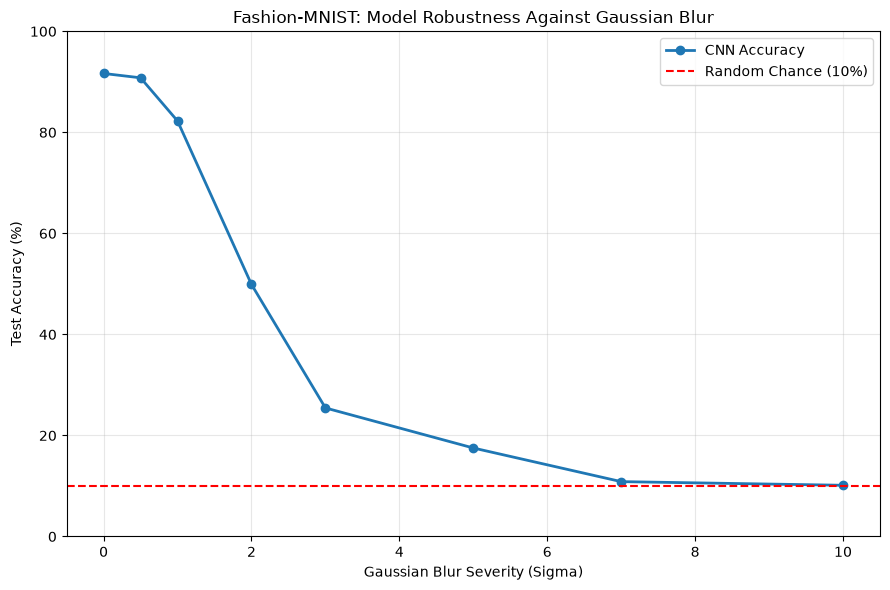

In [23]:

# Step 4: Test model robustness against Gaussian blur

# Increasing blur severity (standard deviation)
blur_levels = [0, 0.5, 1, 2, 3, 5, 7, 10]
blur_accuracies = []

for sigma in blur_levels:

    if sigma == 0:
        # No blur: baseline accuracy
        accuracy = baseline_accuracy
    else:
        # Apply Gaussian blur before converting to tensor
        blur_transform = transforms.Compose([
            transforms.GaussianBlur(
                kernel_size=27,
                sigma=sigma
            ),
            transforms.ToTensor()
        ])

        blurred_dataset = datasets.FashionMNIST(
            root="./data",
            train=False,
            download=False,
            transform=blur_transform
        )

        blurred_loader = DataLoader(
            blurred_dataset,
            batch_size=64,
            shuffle=False
        )

        accuracy = evaluate_model(
            model, blurred_loader, device
        )

    blur_accuracies.append(accuracy)
    print(f"Blur sigma: {sigma} | Accuracy: {accuracy:.2f}%")

# Plot accuracy against blur severity
plt.figure(figsize=(9, 6))

plt.plot(
    blur_levels,
    blur_accuracies,
    marker="o",
    linewidth=2,
    label="CNN Accuracy"
)

plt.axhline(
    y=10,
    color="red",
    linestyle="--",
    label="Random Chance (10%)"
)

plt.xlabel("Gaussian Blur Severity (Sigma)")
plt.ylabel("Test Accuracy (%)")
plt.title("Fashion-MNIST: Model Robustness Against Gaussian Blur")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Step 5 - Robustness Test the Model Against a Transform of Your Choice

Repeat Step 4 for a transform of your choice. Create a plot showing how model accuracy changes as the transformation is applied more drastically. Briefly explain why you selected this transform, how you parameterized its severity, and what the results tell you about your model's robustness. Compare the results with your blur experiment. When selecting transformations, and when determining the degree to which they should be applied, consider whether the original image labels remain valid after the transformation is applied. For example, a 6 rotated far enough may become visually indistinguishable from a 9!

As in Step 4, include the untransformed baseline and use the same test samples across all transformation levels.

What I picked as my second transformation was contrast because changes in lighting along with the type of quality for the images can affect how well the model can figure out what clothing it is. I tested different contrast characteristics from 0.0 to 2.0, with 1.0 being the original image. The lower the contrast the more it effects the differences within the specific dark and light areas and makes it less noticeable. The higher factors raise those differences making the details more visible. This experiment allows me to see how the model is very good at finding the changes in image contrast. The results showed that the model had about 91.7% accuracy with the original images, but when the contrast was completely removed the accuracy dropped to 10%. At a contrast factor of 0.6 the accuracy was around 70%, while the higher contrast factors stayed around 90%. Compared to Gaussian blur that takes out the images details, contrast changes effect how clearly those details appear. Both tests help identify the model's limitations when classifying images under different conditions. Overall the model seems to do better when the image details are more visible but struggles when those details are harder to recognize.

Contrast factor: 1.0 | Accuracy: 91.66%
Contrast factor: 0.8 | Accuracy: 86.51%
Contrast factor: 0.6 | Accuracy: 70.09%
Contrast factor: 0.4 | Accuracy: 44.25%
Contrast factor: 0.2 | Accuracy: 18.59%
Contrast factor: 0.1 | Accuracy: 10.05%
Contrast factor: 0.0 | Accuracy: 10.00%
Contrast factor: 1.5 | Accuracy: 91.05%
Contrast factor: 2.0 | Accuracy: 90.58%


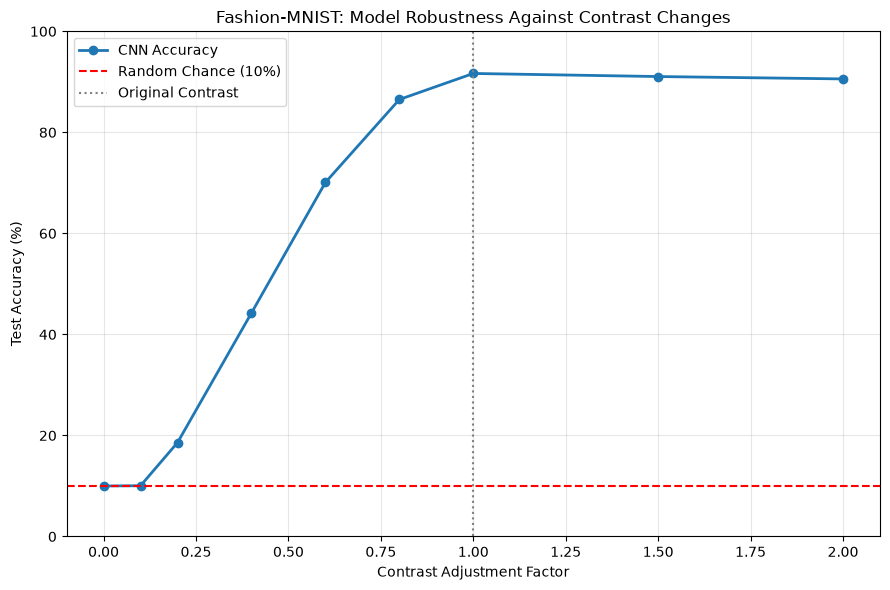

In [24]:

# Step 5: Test model robustness against contrast changes

# Contrast factor: 1.0 = original image
# 0.0 = no contrast, 2.0 = increased contrast
contrast_levels = [1.0, 0.8, 0.6, 0.4, 0.2, 0.1, 0.0, 1.5, 2.0]
contrast_accuracies = []

for factor in contrast_levels:

    if factor == 1.0:
        accuracy = baseline_accuracy
    else:
        contrast_transform = transforms.Compose([
            transforms.Lambda(
                lambda img, f=factor: transforms.functional.adjust_contrast(
                    img, f
                )
            ),
            transforms.ToTensor()
        ])

        contrast_dataset = datasets.FashionMNIST(
            root="./data",
            train=False,
            download=False,
            transform=contrast_transform
        )

        contrast_loader = DataLoader(
            contrast_dataset,
            batch_size=64,
            shuffle=False
        )

        accuracy = evaluate_model(
            model, contrast_loader, device
        )

    contrast_accuracies.append(accuracy)
    print(
        f"Contrast factor: {factor} | "
        f"Accuracy: {accuracy:.2f}%"
    )

# Sort values for a continuous plot
sorted_results = sorted(
    zip(contrast_levels, contrast_accuracies)
)

sorted_levels, sorted_accuracies = zip(*sorted_results)

plt.figure(figsize=(9, 6))

plt.plot(
    sorted_levels,
    sorted_accuracies,
    marker="o",
    linewidth=2,
    label="CNN Accuracy"
)

plt.axhline(
    y=10,
    color="red",
    linestyle="--",
    label="Random Chance (10%)"
)

plt.axvline(
    x=1.0,
    color="gray",
    linestyle=":",
    label="Original Contrast"
)

plt.xlabel("Contrast Adjustment Factor")
plt.ylabel("Test Accuracy (%)")
plt.title("Fashion-MNIST: Model Robustness Against Contrast Changes")
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
